# Stefan problem: integral form method

Front position from the integral form, Backward Euler for the finite element coefficients $W$. The Stefan condition method is in `Stefan_notebook_forward_euler.ipynb`; both notebooks use `params.py` and `functions.py`.

In [1]:
import os
import numpy as np
from scipy.sparse.linalg import spsolve
import matplotlib.pyplot as plt

from params import m_L, a_L, mu, T, s0, T_eoc
from functions import assemble, lam, s_exact, m_exact, l2_error, l2_norm, eoc_table

os.makedirs("figures", exist_ok=True)   # all plots are saved here
os.makedirs("tables", exist_ok=True)    # LaTeX tables, \input{tables/...} in the report

## Parameters

In [2]:
# Material data (SI units) and final time T: see params.py

# Discretisation (change these)
Nt = 50       # number of (uniform) time steps
Ny = 40       # number of elements on [0, 1]

t = np.linspace(0.0, T, Nt + 1)
y = np.linspace(0.0, 1.0, Ny + 1)

## Time stepping

In [3]:
def solve_stefan(t, y, s0=0, history=False):
    M, K, C, b = assemble(y)
    g = m_L * (1 - y)                    # lifting of the boundary values
    W = -g[1:-1]                         # initial data m(x, 0) = 0
    sigma = np.zeros(len(t))             # sigma = s^2
    sigma[0] = s0**2
    if history:
        m_all = np.zeros((len(t), len(y)))   # nodal temperatures at all time levels
        m_all[0] = np.r_[0, W, 0] + g

    for n in range(1, len(t)):
        dt = t[n] - t[n - 1]
        sigma[n] = (mu * s0**2 + 2 * a_L * m_L * t[n]) / (mu + m_L / 3 + 2 * b @ W)   # integral form
        ds = sigma[n] - sigma[n - 1]
        A = sigma[n] * M + dt * a_L * K - 0.5 * ds * C
        rhs = sigma[n] * (M @ W) - 0.5 * m_L * ds * b
        W = spsolve(A, rhs)              # Backward Euler for W
        if history:
            m_all[n] = np.r_[0, W, 0] + g

    s = np.sqrt(sigma)
    m = m_all if history else np.r_[0, W, 0] + g    # nodal temperatures at all t (history) or at t[-1]
    return s, s[-1] * y, m               # s at all time levels, nodes x = y s at t[-1] and temperatures

s_h, x_h, m_hist = solve_stefan(t, y, history=True)

## Analytical (Neumann) solution

In [4]:
print(f"lambda = {lam:.6f}")
print(f"s_h(T) = {s_h[-1]*1e3:.5f} mm,  s(T) = {s_exact(T)*1e3:.5f} mm,  "
      f"rel. error = {abs(s_h[-1] - s_exact(T)) / s_exact(T):.2e}")
print(f"L2 error of m at T = {l2_error(x_h, m_hist[-1], T):.3e}")

lambda = 0.246225
s_h(T) = 10.84442 mm,  s(T) = 10.84442 mm,  rel. error = 2.53e-07
L2 error of m at T = 3.985e-06


## Correctness: front position and temperature

Front position against the Neumann solution, and the temperature in the $(t, x)$ plane: the FEM solution $m_h(x, t)$ on the moving mesh $x = s_h(t)\,y$ next to the analytical $m(x, t)$, on the same colour scale. Right of the front the material is solid, $m = 0$.

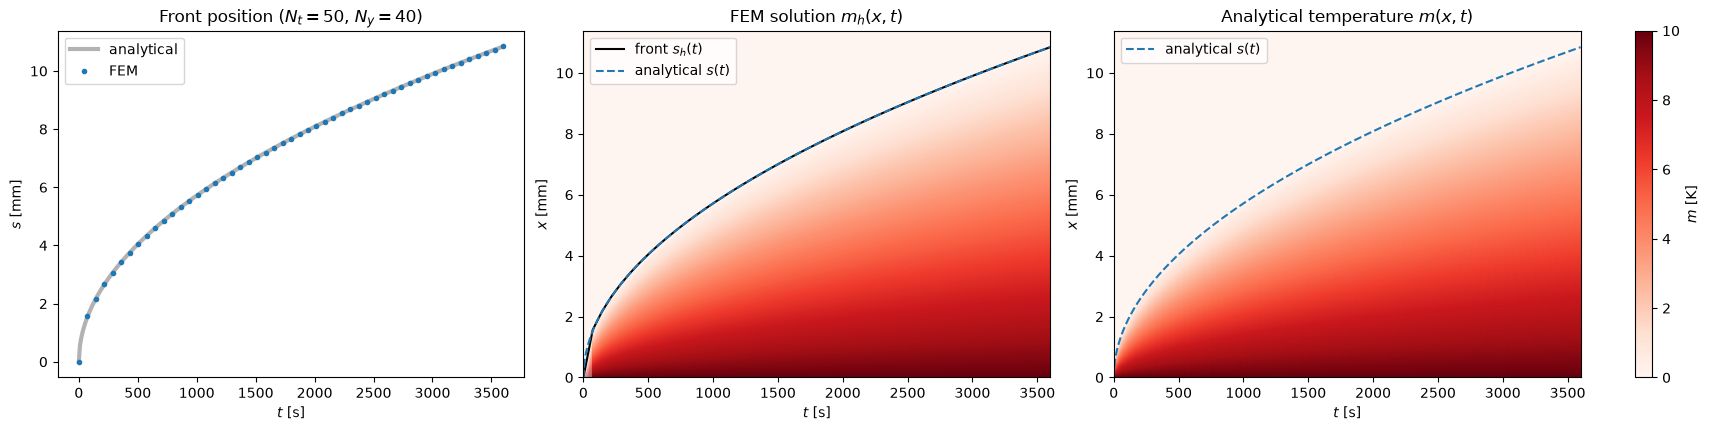

In [5]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.2), layout="constrained")

t_fine = np.linspace(0, T, 400)
ax1.plot(t_fine, 1e3 * s_exact(t_fine), "k-", lw=3, alpha=0.3, label="analytical")
ax1.plot(t, 1e3 * s_h, "C0.", label="FEM")
ax1.set(xlabel="$t$ [s]", ylabel="$s$ [mm]", title=f"Front position ($N_t = {Nt}$, $N_y = {Ny}$)")
ax1.legend()

x_max = 1.05 * s_exact(T)                # extra column of solid (m = 0) up to x_max
X = 1e3 * np.c_[s_h[:, None] * y, np.full(len(t), x_max)]
Tg = np.broadcast_to(t[:, None], X.shape)
heat = dict(cmap="Reds", shading="gouraud", vmin=0, vmax=m_L)
pc = ax2.pcolormesh(Tg, X, np.c_[m_hist, np.zeros(len(t))], **heat)
ax2.plot(t, 1e3 * s_h, "k-", lw=1.5, label="front $s_h(t)$")
ax2.plot(t_fine, 1e3 * s_exact(t_fine), "C0--", lw=1.5, label="analytical $s(t)$")
ax2.set(title="FEM solution $m_h(x, t)$")

t_ex, x_ex = np.meshgrid(t_fine[1:], np.linspace(0, x_max, 300), indexing="ij")   # t > 0, s(0) = 0
ax3.pcolormesh(t_ex, 1e3 * x_ex, m_exact(x_ex, t_ex), **heat)
ax3.plot(t_fine, 1e3 * s_exact(t_fine), "C0--", lw=1.5, label="analytical $s(t)$")
ax3.set(title="Analytical temperature $m(x, t)$")

for ax in (ax2, ax3):
    ax.set(xlabel="$t$ [s]", ylabel="$x$ [mm]", xlim=(0, T), ylim=(0, 1e3 * x_max))
    ax.legend(loc="upper left")
fig.colorbar(pc, ax=[ax2, ax3], label="$m$ [K]")
fig.savefig("figures/correctness.pdf")
plt.show()

In [6]:
def error_at_T(Nt, Ny):
    t = np.linspace(0.0, T, Nt + 1)
    y = np.linspace(0.0, 1.0, Ny + 1)
    s_h, x_h, m_h = solve_stefan(t, y)
    s_err = abs(s_h[-1] - s_exact(T))    # front position error at T
    m_err = l2_error(x_h, m_h, T)        # L2 error of the temperature at T
    return s_err, m_err

## Spatial order of convergence

Errors at $T$ against the Neumann solution, with a fine time grid.

In [7]:
Nt_fine = 2000
Ny_list = 10 * 2**np.arange(7)           # 10, 20, ..., 640
err_space = np.array([error_at_T(Nt_fine, ny) for ny in Ny_list])
eoc_table("tables/eoc_space.tex", "N_y", Ny_list, err_space[:, 0], err_space[:, 1])

     N_y          e_s     EOC          e_m     EOC
      10    4.385e-08      --    6.370e-05      --
      20    1.098e-08   1.998    1.594e-05   1.999
      40    2.746e-09   1.999    3.985e-06   2.000
      80    6.865e-10   2.000    9.963e-07   2.000
     160    1.716e-10   2.000    2.491e-07   2.000
     320    4.291e-11   2.000    6.227e-08   2.000
     640    1.073e-11   2.000    1.557e-08   2.000
saved to tables/eoc_space.tex


## Temporal convergence

For $s_0 = 0$ the exact solution in $y$ does not change in time, so the time error dies out after a few time steps and only the spatial error remains.

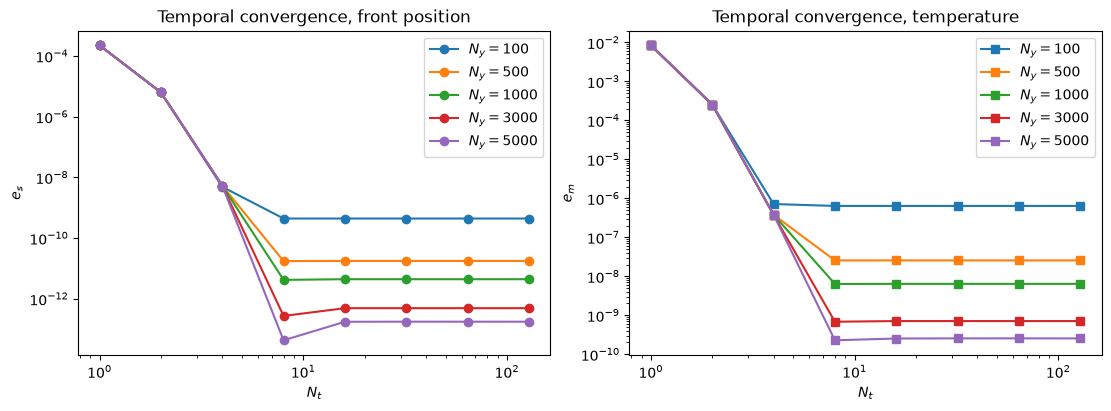

In [8]:
# Temporal convergence: vary Nt for a few spatial grids
Ny_time = [100, 500, 1000, 3000, 5000]
Nt_list = np.array([1, 2, 4, 8, 16, 32, 64, 128])
err_time = np.array([[error_at_T(Nt, ny) for Nt in Nt_list] for ny in Ny_time])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for i, ny in enumerate(Ny_time):
    ax1.loglog(Nt_list, err_time[i, :, 0], f"C{i}o-", label=f"$N_y = {ny}$")
    ax2.loglog(Nt_list, err_time[i, :, 1], f"C{i}s-", label=f"$N_y = {ny}$")
ax1.set(xlabel="$N_t$", ylabel="$e_s$", title="Temporal convergence, front position")
ax2.set(xlabel="$N_t$", ylabel="$e_m$", title="Temporal convergence, temperature")
ax1.legend()
ax2.legend()
fig.savefig("figures/convergence_time.pdf")
plt.show()

## Temporal order of convergence ($s_0 > 0$)

Now the solution in $y$ changes in time, so the error is measured against a reference solution with $N_t^{ref}$ time steps on the same spatial grid; the temperature error is the $L^2$ norm in $y$.

In [9]:
# s0 and final time T_eoc: see params.py
Ny_eoc = 100
Nt_ref = 2**14
Nt_eoc = 2**np.arange(2, 9)
y_eoc = np.linspace(0.0, 1.0, Ny_eoc + 1)

t_ref = np.linspace(0.0, T_eoc, Nt_ref + 1)
s_ref, _, m_ref = solve_stefan(t_ref, y_eoc, s0)
sols = [solve_stefan(np.linspace(0.0, T_eoc, Nt + 1), y_eoc, s0) for Nt in Nt_eoc]
err_s = np.array([abs(s[-1] - s_ref[-1]) for s, x, m in sols])
err_m = np.array([l2_norm(y_eoc, m - m_ref) for s, x, m in sols])   # L2 norm in y
print(f"s(T) - s0 = {1e3 * (s_ref[-1] - s0):.4f} mm")
eoc_table("tables/eoc_time.tex", "N_t", Nt_eoc, err_s, err_m)

s(T) - s0 = 0.0990 mm
     N_t          e_s     EOC          e_m     EOC
       4    3.036e-04      --    2.219e-01      --
       8    1.537e-04   0.982    1.133e-01   0.970
      16    7.739e-05   0.990    5.717e-02   0.987
      32    3.881e-05   0.996    2.869e-02   0.995
      64    1.940e-05   1.000    1.435e-02   1.000
     128    9.674e-06   1.004    7.154e-03   1.004
     256    4.801e-06   1.011    3.551e-03   1.011
saved to tables/eoc_time.tex
